# 🌌 EPB Detection System — V5

Module: `epb_detection_system_v5.py` (reuses `epb_detection_system_v2.py` without changing it).

### Changes from V4, in priority order
1. **Signed detrending** δI/I = I / background − 1, with no clipping. In V4, `img − background` followed by `clip(·, 0)` set depletions (the bubbles themselves) to zero.
2. **Star removal** (morphological opening, removes only small bright points) + **radial flattening** (horizon brightening and vignetting) + **background estimated only inside the dome**.
3. **z-score inside the dome** in place of CLAHE. Processing at 512 px and downsampling at the end (`order='fullres'`) was tested and **is not the default**: per night it was worse than downsampling to 64 px first. It stays in the ladder as an alternative.
4. **Bubble orientation check per station** (structure tensor), with optional rotation per station.
5. **Simple classifier**: 2DPCA + StandardScaler + Logistic Regression, no SMOTE. Stacking is kept for comparison.

### Labels
Frames with `cloudy=1` have `has_epb` empty (EPB undetermined). They are excluded from Stage 2 (EPB classifier) and used only to evaluate Stage 1 (sky quality control).

### Evaluation
The unit of evaluation is the **observation night** (each night has a single class). Every result below is **leave-one-night-out**. Hyperparameters ($k$ of the 2DPCA and $C$ of the regression) are chosen by **nested** leave-one-night-out: the outer night never takes part in the choice. Frame-level results appear only as an optimistic reference.

**Author:** Alberto Ivo da Costa Vieira

In [1]:
import os, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

import epb_detection_system_v5 as v5
from epb_detection_system_v2 import (
    extract_night_groups, EPBRecognitionSystem, EPBModelData, save_model,
    plot_performance_metrics, plot_confusion_matrix_analysis, _binary_metrics, setup_logging,
)

setup_logging(logging.WARNING)
np.random.seed(42)

DATA_FOLDER = "data/all-images"
LABEL_FILE = "data/epb_labels.csv"
TARGET_SIZE = (64, 64)
RESULTS_DIR = "results_v5"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Hyperparameter grid (chosen by nested leave-one-night-out)
PARAM_GRID = {"n_components": [3, 5, 10], "C": [0.001, 0.01, 0.1]}

# V4 stacking hyperparameters (comparison only)
ENSEMBLE_PARAMS = {"svm_C": 5.0, "svm_gamma": "scale", "xgb_n_estimators": 200, "xgb_max_depth": 6,
                   "xgb_learning_rate": 0.1, "rf_n_estimators": 200, "rf_max_depth": 15, "meta_C": 1.0}
MODEL_VERSION = "5.0"

In [2]:
# ========== DATA (512 px originals) AND OBSERVATION NIGHTS ==========
# Stage 2 (EPB): clear-sky frames only. Cloudy frames (has_epb empty) have undetermined EPB.
raw, y, df_labels = v5.load_raw_dataset(DATA_FOLDER, LABEL_FILE)
nights = extract_night_groups(df_labels)
sites = df_labels["site"].values
# Stage 1 (QC): all frames, including the cloudy ones (y = -1)
raw_all, y_all, df_all = v5.load_raw_dataset(DATA_FOLDER, LABEL_FILE, include_cloudy=True)
nights_all = extract_night_groups(df_all)
print(f"Stage 2: {len(raw)} clear-sky frames | Stage 1: {len(raw_all)} frames "
      f"({int((y_all == -1).sum())} cloudy, EPB undetermined) | resolution {raw.shape[1]}x{raw.shape[2]}")

df_nights = (pd.DataFrame({"night": nights, "has_epb": y, "cloudy": df_labels["cloudy"].values,
                           "moon": df_labels["moon_illumination"].values})
             .groupby("night").agg(frames=("has_epb", "size"), epb_frames=("has_epb", "sum"),
                                   cloudy_frames=("cloudy", "sum"), mean_moon_pct=("moon", "mean")))
df_nights["class"] = np.where(df_nights["epb_frames"] == df_nights["frames"], "EPB",
                              np.where(df_nights["epb_frames"] == 0, "No EPB", "mixed"))
print(df_nights.round(1).to_string())

Stage 2: 510 clear-sky frames | Stage 1: 572 frames (62 cloudy, EPB undetermined) | resolution 512x512
              frames  epb_frames  cloudy_frames  mean_moon_pct   class
night                                                                 
BJL_20250722     220           0              0            3.8  No EPB
CA_20250407       35           0              0           80.4  No EPB
CA_20251022       85          85              0            2.2     EPB
CA_20251027       42          42              0           34.3     EPB
CA_20251218       86          86              0            1.1     EPB
CP_20240209       42          42              0            0.2     EPB


## Stage 1 — Sky quality control vs. the manual `cloudy` label
Cloudy is an observation condition, not a state of the ionosphere: on a cloudy frame nobody can tell whether there is an EPB. The system therefore reports **three verdicts**: `EPB`, `Sem EPB` and `Indeterminado` (cloudy sky, no EPB decision). Frames with partial visibility get a decision marked *conferir*.

Thresholds (`v5.QC_PARAMS`, three zones) were tuned on the only labelled cloudy night, so the numbers below are optimistic until cloudy frames from other nights are labelled.

In [3]:
qc_eval = v5.evaluate_stage1_qc(raw_all, df_all, nights_all)
qc_eval["summary"].to_csv(f"{RESULTS_DIR}/stage1_qc_summary.csv", index=False)
qc_eval["per_night"].to_csv(f"{RESULTS_DIR}/stage1_qc_per_night.csv", index=False)


☁️  Stage 1 QC vs. manual `cloudy` label (572.0 frames, 62.0 cloudy from 1.0 night(s))
   • Cloudy -> 'Indeterminado' (recall):  54.8%  (34/62)
   • Cloudy -> decision marked 'conferir': 24.2%
   • Clear frames passed to Stage 2:      96.3%  (491/510); worst clear night 81.0%
   • Precision of 'Indeterminado':        64.2%
       night  frames  cloudy_labeled  qc_blocked  degraded  median_stars  qc_blocked_pct
BJL_20250722     220               0           0         6       11795.5             0.0
 CA_20250407      35               0           0         2       22163.0             0.0
 CA_20251022      85               0           0         0        8712.0             0.0
 CA_20251027      42               0           8        10        5029.5            19.0
 CA_20251218      86               0          11        19        7825.5            12.8
 CA_20260624      62              62          34        15        1407.0            54.8
 CP_20240209      42               0           0   

## Preprocessing: V4 vs. V5

💾 Figure saved: results_v5/preprocessing_v4_vs_v5.png


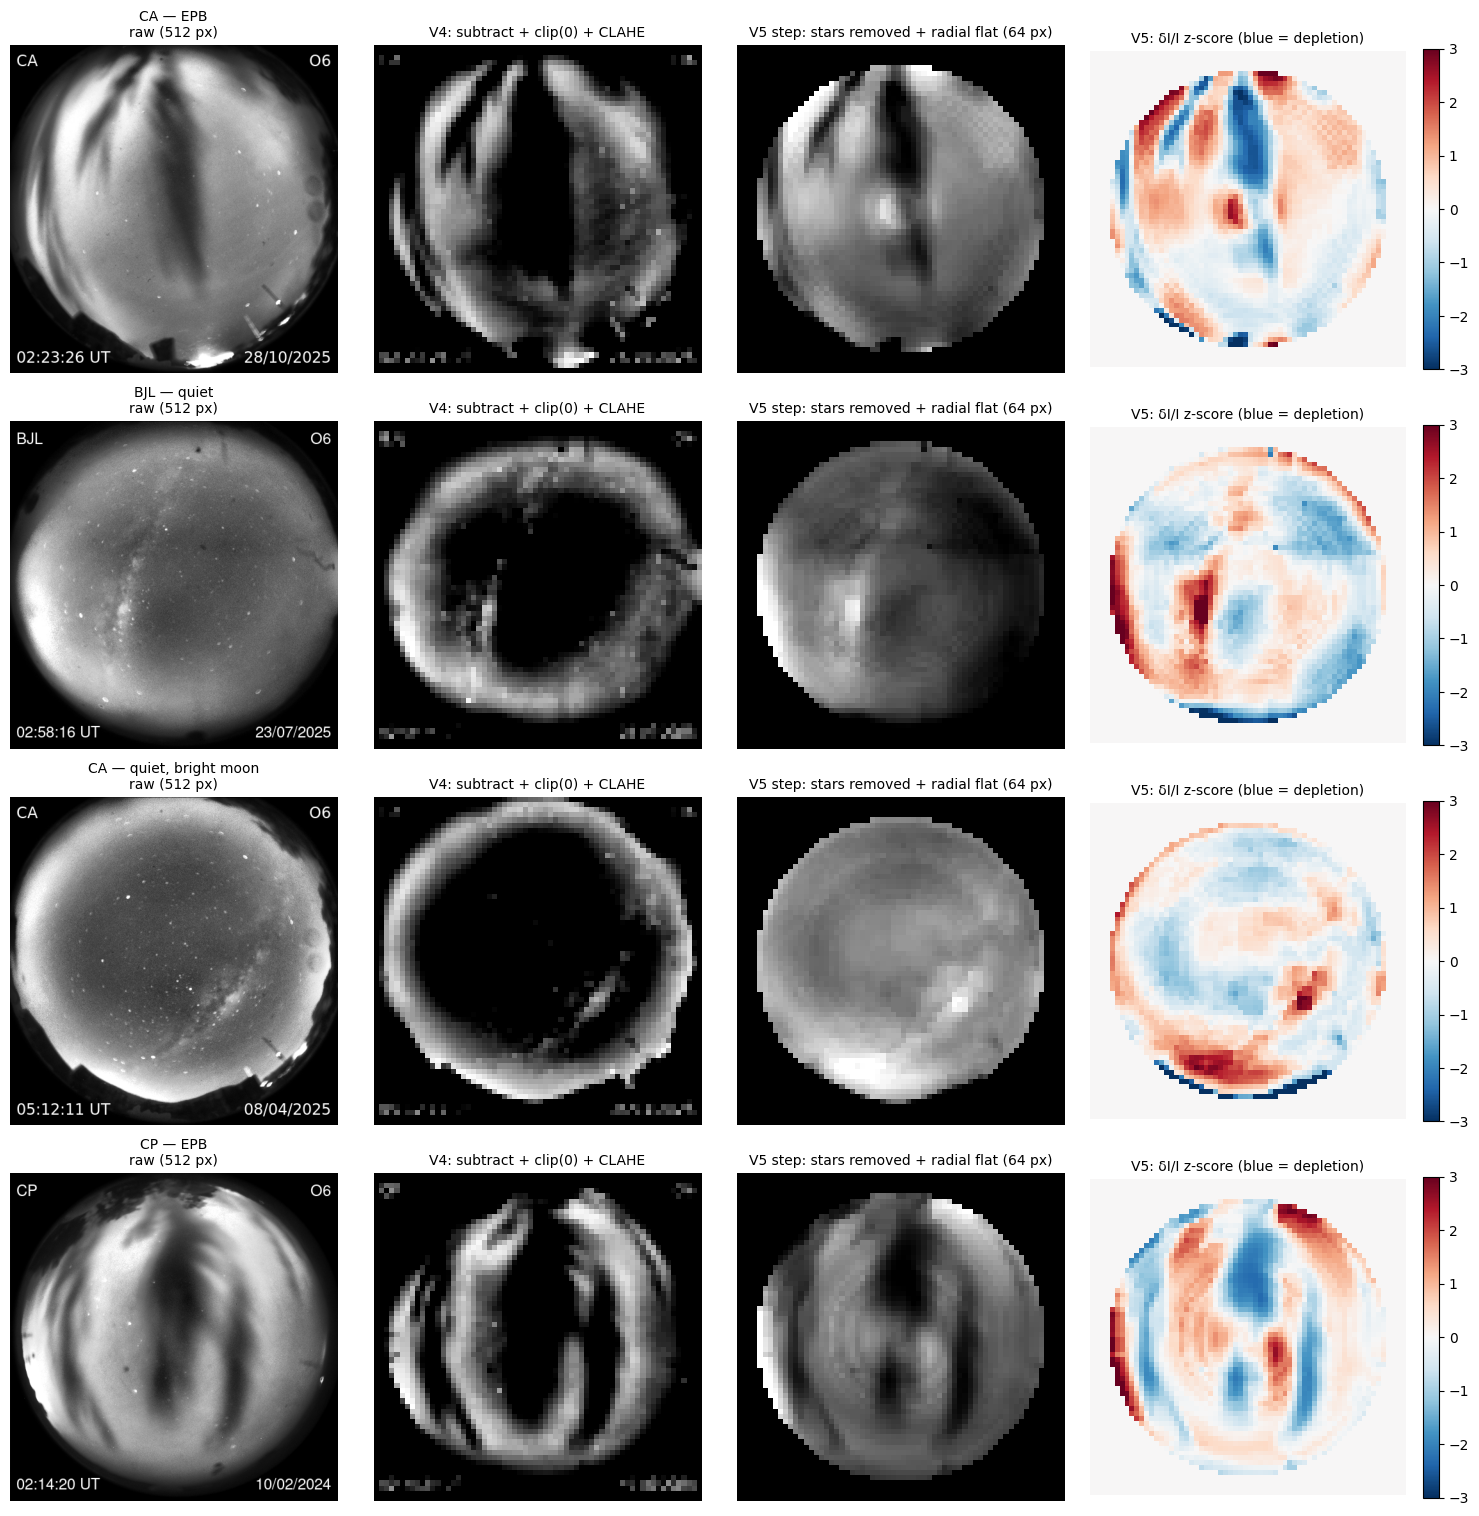

In [4]:
from PIL import Image
examples = [
    ("CA — EPB", "O6_CA_20251028_022326.png"),
    ("BJL — quiet", "O6_BJL_20250723_025816.png"),
    ("CA — quiet, bright moon", "O6_CA_20250408_051211.png"),
    ("CP — EPB", "O6_CP_20240210_021420.png"),
]
raw_examples = [(t, np.array(Image.open(f"{DATA_FOLDER}/{f}").convert("L"))) for t, f in examples]
fig = v5.plot_preprocessing_comparison(raw_examples, TARGET_SIZE,
                                       save_path=f"{RESULTS_DIR}/preprocessing_v4_vs_v5.png")
plt.show()

## Item 4 — Bubble orientation per station
Bubbles follow the magnetic meridian. If a station recorded with another orientation, the same bubble would appear in another direction and the 2DPCA components would stop being comparable. Measured on EPB frames only.

In [5]:
X_v5 = v5.preprocess_batch(raw, target_size=TARGET_SIZE, **v5.V5_PREPROCESS)
df_orient = v5.check_station_orientation(X_v5, y, sites)
df_orient.to_csv(f"{RESULTS_DIR}/station_orientation.csv", index=False)

# Rotation applied per station (degrees). Empty = none: stations with EPB agree to within the tolerance.
needs = df_orient[df_orient["status"].str.startswith("tilted")]
ROTATION_BY_SITE = {r.station: -r.band_angle_deg for r in needs.itertuples()}
print(f"\nROTATION_BY_SITE = {ROTATION_BY_SITE}")
if ROTATION_BY_SITE:
    X_v5 = v5.preprocess_batch(raw, sites=sites, rotation_by_site=ROTATION_BY_SITE,
                               target_size=TARGET_SIZE, **v5.V5_PREPROCESS)


🧭 Band orientation per station (EPB frames only; 0° = vertical bands):
station  epb_frames  band_angle_deg  circular_spread_deg  median_coherence                         status
    BJL           0             NaN                  NaN               NaN not verifiable (no EPB frames)
     CA         213             5.4                 20.9             0.625     consistent (near vertical)
     CP          42             0.5                  6.1             0.565     consistent (near vertical)
   Max difference between stations: 4.9°
   ⚠️  Not verifiable from EPB bands: BJL. Confirm their orientation from the camera setup or star positions.

ROTATION_BY_SITE = {}


## Items 1–3 — Preprocessing ablation ladder
Each step adds one change. All of them use the same classifier (2DPCA + logistic regression) and the same nested selection of $k$ and $C$.

In [6]:
df_ladder, df_ladder_nights, ladder_cache = v5.preprocessing_ladder(
    raw, y, nights, PARAM_GRID, sites=sites, rotation_by_site=ROTATION_BY_SITE)
df_ladder_nights.insert(0, "class", df_nights["class"])
print("\nNested leave-one-night-out:")
print(df_ladder.round(3).to_string(index=False))
print("\nPer-night accuracy:")
print(df_ladder_nights.round(2).to_string())
df_ladder.to_csv(f"{RESULTS_DIR}/preprocessing_ladder.csv", index=False)
df_ladder_nights.to_csv(f"{RESULTS_DIR}/preprocessing_ladder_per_night.csv")

   ✓ V4 equivalent (subtract + clip + CLAHE)          bal.acc=0.663  spec=0.345  sens=0.980  AUC=0.823


   ✓ +1 signed δI/I (no clip)                         bal.acc=0.684  spec=0.396  sens=0.973  AUC=0.906


   ✓ +2 star removal + background inside dome         bal.acc=0.786  spec=0.608  sens=0.965  AUC=0.950


   ✓ +2 radial flattening (= V5 default)              bal.acc=0.512  spec=0.082  sens=0.941  AUC=0.791


   ✓ alt. 3: full-res processing, downsample last     bal.acc=0.461  spec=0.000  sens=0.922  AUC=0.716

Nested leave-one-night-out:
                                        step  accuracy  balanced_accuracy  sensitivity  specificity   auc  macro_night_accuracy  worst_night_accuracy
     V4 equivalent (subtract + clip + CLAHE)     0.663              0.663        0.980        0.345 0.823                 0.764                 0.286
                    +1 signed δI/I (no clip)     0.684              0.684        0.973        0.396 0.906                 0.742                 0.086
    +2 star removal + background inside dome     0.786              0.786        0.965        0.608 0.950                 0.867                 0.591
         +2 radial flattening (= V5 default)     0.512              0.512        0.941        0.082 0.791                 0.685                 0.059
alt. 3: full-res processing, downsample last     0.461              0.461        0.922        0.000 0.716             

## Item 5 — Classifier
V5 preprocessing for every model. Linear models use nested selection. Stacking uses the fixed V4 hyperparameters (non-nested: if anything, its estimate is optimistic).

                                          model  accuracy  sensitivity  specificity   auc  balanced_accuracy  worst_night_accuracy
                        2DPCA + logreg (nested)     0.512        0.941        0.082 0.791              0.512                 0.059
                    2DPCA + svm_linear (nested)     0.457        0.914        0.000 0.651              0.457                 0.000
       2DPCA (k=5) + stacking, V5 preprocessing     0.476        0.953        0.000 0.023              0.476                 0.000
V4 system (V4 preprocessing + stacking + SMOTE)     0.541        0.984        0.098 0.443              0.541                 0.000

Parameters chosen per outer night (logreg):
       night                        selection  n_components     C
BJL_20250722 fixed (inner loop had one class)             5 0.001
 CA_20250407 fixed (inner loop had one class)             5 0.001
 CA_20251022                           nested             5 0.001
 CA_20251027                        

💾 Gráfico salvo: results_v5/roc_pr_curves_logo.png (200 DPI)
💾 Gráfico salvo: results_v5/confusion_matrix_logo.png (200 DPI)


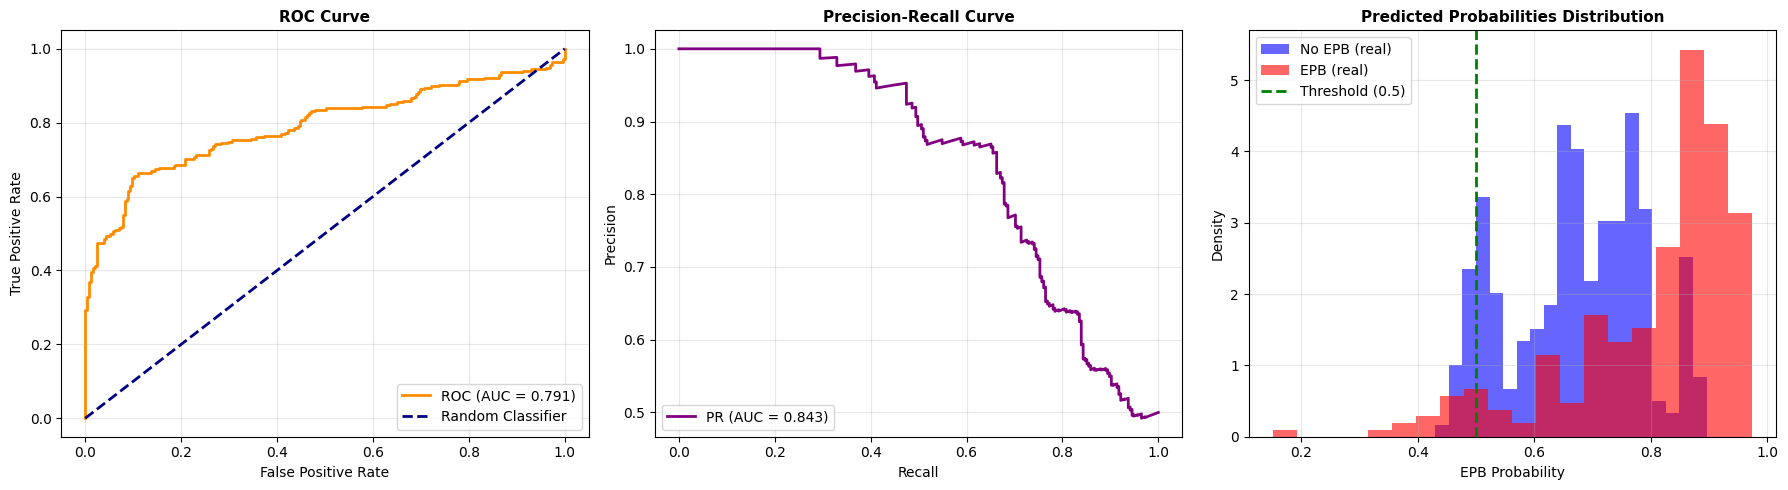

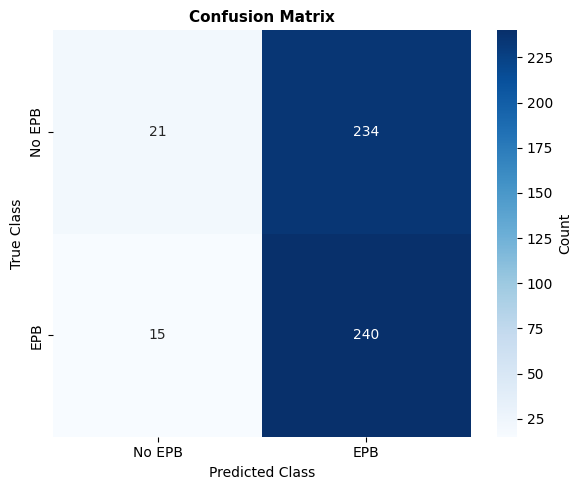

In [7]:
def _row(name, pred, proba):
    ok = pred >= 0                      # -1 = night without prediction (single-class training split)
    m = _binary_metrics(y[ok], pred[ok], proba[ok])
    accs = [np.mean(pred[nights == n] == y[nights == n]) for n in np.unique(nights) if ok[nights == n].all()]
    return {"model": name, "accuracy": m["accuracy"], "sensitivity": m["sensitivity"],
            "specificity": m["specificity"], "auc": m["auc"],
            "balanced_accuracy": np.nanmean([m["sensitivity"], m["specificity"]]),
            "worst_night_accuracy": min(accs)}

rows, oof = [], {}
for clf in ["logreg", "svm_linear"]:
    res = v5.nested_logo_evaluate(
        X_v5, y, nights, PARAM_GRID,
        lambda clf=clf, **kw: v5.EPBRecognitionSystemV5(classifier=clf, **kw), verbose=False)
    oof[clf] = res
    rows.append(_row(f"2DPCA + {clf} (nested)", res["y_pred"], res["y_proba"]))

for k in [5]:
    pred, proba = v5.logo_predict(X_v5, y, nights, lambda: v5.EPBRecognitionSystemV5(
        n_components=k, classifier="stacking", ensemble_params=ENSEMBLE_PARAMS))
    rows.append(_row(f"2DPCA (k={k}) + stacking, V5 preprocessing", pred, proba))

X_v4 = ladder_cache[v5.PREPROCESS_LADDER[0][0]]
pred, proba = v5.logo_predict(X_v4, y, nights, lambda: EPBRecognitionSystem(
    n_components=5, balance_data=True, balance_method="smote", ensemble_params=ENSEMBLE_PARAMS))
rows.append(_row("V4 system (V4 preprocessing + stacking + SMOTE)", pred, proba))

df_clf = pd.DataFrame(rows)
print(df_clf.round(3).to_string(index=False))
df_clf.to_csv(f"{RESULTS_DIR}/classifier_comparison.csv", index=False)

res_main = oof["logreg"]
print("\nParameters chosen per outer night (logreg):")
print(res_main["chosen"].to_string(index=False))
plot_performance_metrics(y, res_main["y_proba"], save_path=f"{RESULTS_DIR}/roc_pr_curves_logo.png", dpi=200)
plot_confusion_matrix_analysis(y, res_main["y_pred"], save_path=f"{RESULTS_DIR}/confusion_matrix_logo.png", dpi=200)
plt.show()

## Confounders and frame-level reference
- **Brightness only**: 5 statistics of the raw image (no spatial structure). If it beats the model, the model is not using bubble morphology.
- **Frame-level 5-fold**: frames of the same night on both sides, an optimistic reference. A large gap from the per-night result indicates dependence on recognising the night.

In [8]:
F_bright = v5.brightness_features(raw)

def frame_level(X, make):
    proba = np.zeros(len(y))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=42).split(X, y):
        proba[te] = make().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    return (proba >= 0.5).astype(int), proba

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
class _TabLR:
    def fit(self, F, yy):
        self.p = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=3000)).fit(F, yy)
        return self
    def predict_proba(self, F):
        return self.p.predict_proba(F)

pred_b, proba_b = v5.logo_predict(F_bright, y, nights, lambda: _TabLR())
best_all, _ = v5.select_params_logo(X_v5, y, nights, PARAM_GRID, lambda **kw: v5.EPBRecognitionSystemV5(**kw))
pf, prf = frame_level(X_v5, lambda: v5.EPBRecognitionSystemV5(**best_all))
pbf, prbf = frame_level(F_bright, lambda: _TabLR())

df_conf = pd.DataFrame([
    {"model": "V5 (2DPCA + logreg)", "protocol": "leave-one-night-out (nested)",
     **{k: _row("", res_main["y_pred"], res_main["y_proba"])[k] for k in ["accuracy", "balanced_accuracy", "specificity", "auc"]}},
    {"model": "V5 (2DPCA + logreg)", "protocol": "frame-level 5-fold (optimistic)",
     **{k: _row("", pf, prf)[k] for k in ["accuracy", "balanced_accuracy", "specificity", "auc"]}},
    {"model": "Brightness statistics only", "protocol": "leave-one-night-out",
     **{k: _row("", pred_b, proba_b)[k] for k in ["accuracy", "balanced_accuracy", "specificity", "auc"]}},
    {"model": "Brightness statistics only", "protocol": "frame-level 5-fold (optimistic)",
     **{k: _row("", pbf, prbf)[k] for k in ["accuracy", "balanced_accuracy", "specificity", "auc"]}},
])
print(df_conf.round(3).to_string(index=False))
df_conf.to_csv(f"{RESULTS_DIR}/confounders_v5.csv", index=False)

                     model                        protocol  accuracy  balanced_accuracy  specificity   auc
       V5 (2DPCA + logreg)    leave-one-night-out (nested)     0.512              0.512        0.082 0.791
       V5 (2DPCA + logreg) frame-level 5-fold (optimistic)     0.984              0.984        0.976 0.999
Brightness statistics only             leave-one-night-out     0.959              0.959        0.976 0.991
Brightness statistics only frame-level 5-fold (optimistic)     0.973              0.973        0.984 0.997


## Final model, explainability, and night sequences
The final model is trained on **all** nights using the parameters chosen by leave-one-night-out over all nights. Each night sequence is predicted by a model trained **without** that night.

Final parameters: {'C': 0.001, 'n_components': 5}


💾 Figure saved: results_v5/attribution_O6_CA_20251028_022326.png


💾 Figure saved: results_v5/attribution_O6_BJL_20250723_025816.png


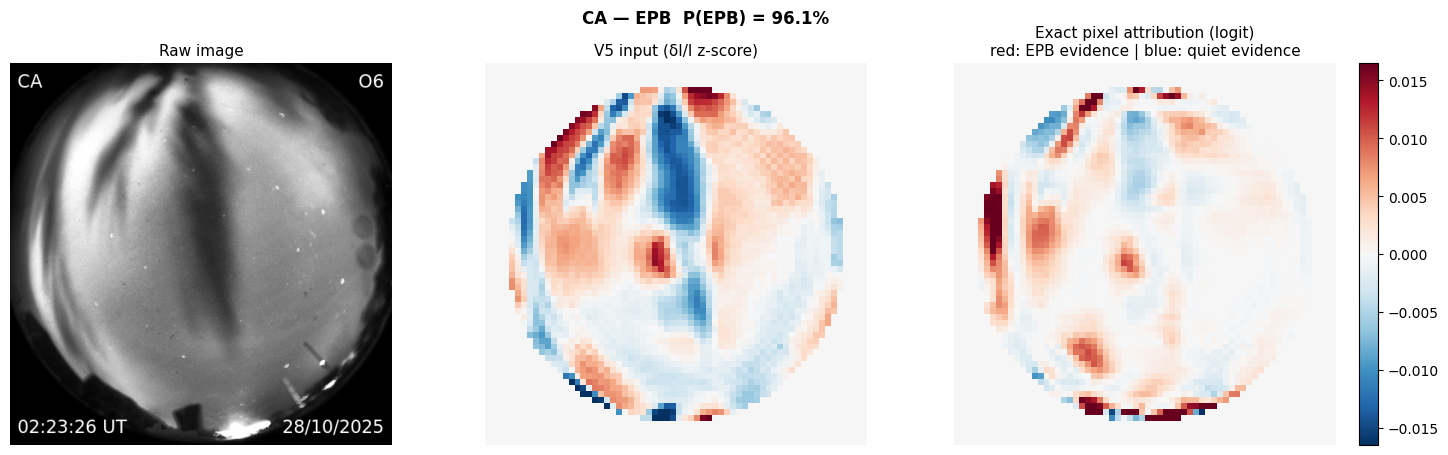

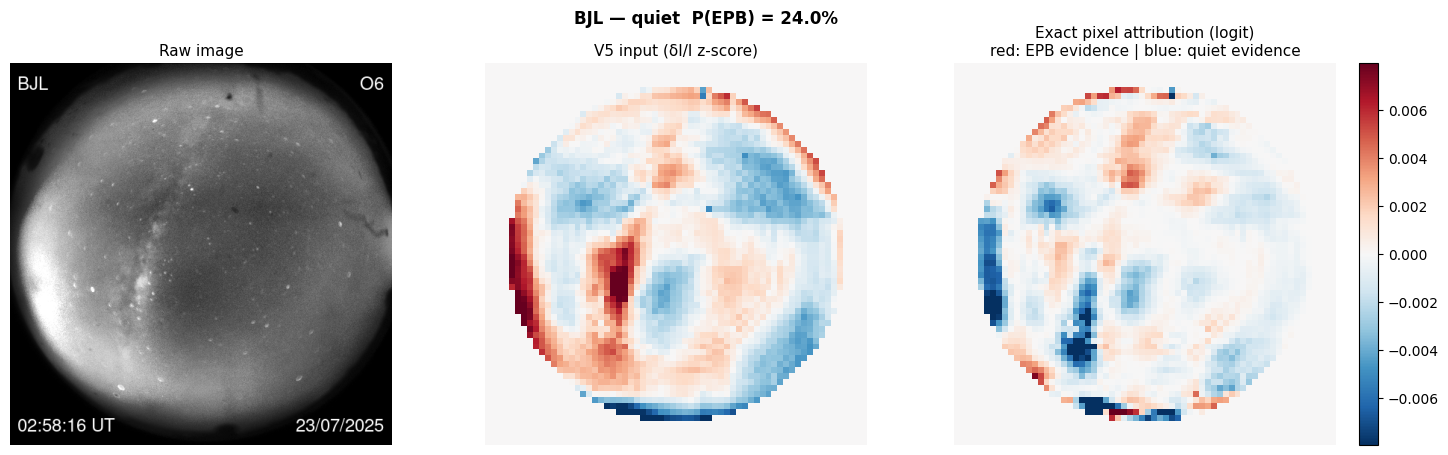

                              sequence  night_labeled_for_stage2  frames  undetermined_pct  stage2_only_epb_pct  cascaded_epb_pct  cascaded_clear_sky_epb_pct
BJL night 2025-07-22/23 (clear, quiet)                      True     230               3.5                 94.3              90.9                        88.3
       CA night 2026-06-24/25 (cloudy)                     False      62              54.8                 64.5              29.0                        11.3
   CA night 2025-10-22/23 (active EPB)                      True     140               1.4                 92.9              92.1                        91.4


In [9]:
print(f"Final parameters: {best_all}")
final = v5.EPBRecognitionSystemV5(rotation_by_site=ROTATION_BY_SITE, target_size=TARGET_SIZE, **best_all)
final.fit(X_v5, y)

# Exact pixel attribution (linear model): one EPB example and one quiet example
for title, fname in [("CA — EPB", "O6_CA_20251028_022326.png"), ("BJL — quiet", "O6_BJL_20250723_025816.png")]:
    r_img = np.array(Image.open(f"{DATA_FOLDER}/{fname}").convert("L"))
    v5.plot_linear_attribution(final, final.preprocess(r_img), X_v5, raw=r_img, title=title,
                               save_path=f"{RESULTS_DIR}/attribution_{fname.replace('.png', '')}.png")
plt.show()

sequences = [
    ("BJL night 2025-07-22/23 (clear, quiet)", "util/BJL_20250722/processed", "BJL_20250722"),
    ("CA night 2026-06-24/25 (cloudy)", "util/CA_20260624/processed", "CA_20260624"),
    ("CA night 2025-10-22/23 (active EPB)", "util/CA_20251022/processed", "CA_20251022"),
]
df_seq = v5.evaluate_sequences_out_of_night(
    X_v5, y, nights, sequences,
    lambda: v5.EPBRecognitionSystemV5(rotation_by_site=ROTATION_BY_SITE, target_size=TARGET_SIZE, **best_all))
print(df_seq.to_string(index=False))
df_seq.to_csv(f"{RESULTS_DIR}/sequences_out_of_night.csv", index=False)

## Report for the specialist (three verdicts per frame)
`final.analyze_folder(folder)` returns one row per frame (`EPB` / `Sem EPB` / `Indeterminado`, probability, sky condition, whether to *conferir*) and a night summary. The EPB rate is computed only over frames with a decision. Note: `final` was trained on these nights, so this cell only demonstrates the report format.

In [10]:
for label, folder, _ in sequences:
    frames_rep, summary_rep = final.analyze_folder(folder)
    print(f"\n{label}")
    print(summary_rep.to_string(index=False))
    frames_rep.to_csv(f"{RESULTS_DIR}/report_{os.path.basename(os.path.dirname(folder))}.csv", index=False)


BJL night 2025-07-22/23 (clear, quiet)
 frames  EPB  Sem EPB  Indeterminado  conferir (visibilidade parcial)  cobertura_pct  epb_pct_dos_decididos
    230    0      222              8                                6           96.5                    0.0



CA night 2026-06-24/25 (cloudy)
 frames  EPB  Sem EPB  Indeterminado  conferir (visibilidade parcial)  cobertura_pct  epb_pct_dos_decididos
     62   18       10             34                               15           45.2                   64.3



CA night 2025-10-22/23 (active EPB)
 frames  EPB  Sem EPB  Indeterminado  conferir (visibilidade parcial)  cobertura_pct  epb_pct_dos_decididos
    140  138        0              2                                2           98.6                  100.0


In [11]:
# ========== SAVE MODEL V5.0 ==========
s = res_main["summary"]
model_data = EPBModelData(
    version=MODEL_VERSION, system=final, n_components=int(best_all["n_components"]), target_size=TARGET_SIZE,
    test_metrics={
        "protocol": "nested leave-one-night-out",
        "logo_accuracy": float(s["accuracy"]),
        "logo_balanced_accuracy": float(s["balanced_accuracy"]),
        "logo_sensitivity": float(s["sensitivity"]),
        "logo_specificity": float(s["specificity"]),
        "logo_auc": float(s["auc"]),
        "logo_worst_night_accuracy": float(s["worst_night_accuracy"]),
        "C": float(best_all["C"]),
    })
h = save_model(model_data, f"models/epb_recognition_model-v{MODEL_VERSION}.pkl")
print(f"✓ models/epb_recognition_model-v{MODEL_VERSION}.pkl  SHA-256 {h[:16]}…")
print("Note: inference needs the raw image (512 px); use final.predict_cascaded(raw) or final.predict_proba_raw(raw).")

✓ models/epb_recognition_model-v5.0.pkl  SHA-256 c88c9d7eb53c8f19…
Note: inference needs the raw image (512 px); use final.predict_cascaded(raw) or final.predict_proba_raw(raw).
